# Wage Case 1: Overdue Receivables
Part of the field tech wage case (see the *Field Tech Wage Case: Analysis Plan* doc).
**Question:** how much money is owed to the company, how old it is, and who holds it, especially public adjusters.
Source: the AR tracker in the company app (Supabase `ar_entries` + `ar_payor_types`). Read-only.

In [1]:
import sys
sys.path.insert(0, "../src")
from supabase_pull import pull
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import Markdown, display
pd.set_option("display.float_format", "{:,.2f}".format)

# Age buckets as stored in the app -> display labels, oldest last
BUCKETS = {"current": "Current", "b1_30": "1-30", "b31_60": "31-60", "b61_90": "61-90",
           "b91_120": "91-120", "b121_150": "121-150", "b151_180": "151-180", "b180plus": "180+"}
OVER_90 = ["91-120", "121-150", "151-180", "180+"]

# Payor types -> groups for the memo. Both public adjuster types count as PA.
GROUPS = {"river_city": "River City Claims (PA)", "public_adjuster": "Other public adjusters",
          "carrier": "Insurance carriers", "attorney": "Attorney", "contractor": "Contractors"}
PA_TYPES = {"river_city", "public_adjuster"}
GROUP_ORDER = list(GROUPS.values()) + ["Not typed"]
PA_COLOR, OTHER_COLOR, INK = "#b42318", "#98a2b3", "#344054"

In [2]:
ar = pull("select * from ar_entries", snapshot="ar_entries")
types = pull("select payor, payor_type, updated_at from ar_payor_types")

# Match payor names ignoring case and stray spaces ("State Farm Insurance " -> "state farm insurance")
key = lambda s: s.astype(str).str.strip().str.lower()
types = types.assign(key=key(types["payor"])).sort_values("updated_at").drop_duplicates("key", keep="last")
ar = ar.assign(key=key(ar["payor"])).merge(types[["key", "payor_type"]], on="key", how="left")

for c in ["balance", "collected", "collectable"]:
    ar[c] = pd.to_numeric(ar[c]).fillna(0.0)
ar["owed"]    = ar["balance"] - ar["collected"]          # what is still outstanding
ar["age"]     = ar["bucket"].map(BUCKETS)
ar["over_90"] = ar["age"].isin(OVER_90)
ar["group"]   = ar["payor_type"].map(GROUPS).fillna("Not typed")
ar["is_pa"]   = ar["payor_type"].isin(PA_TYPES)
ar["payor"]   = ar["payor"].str.strip()

## Data checks

In [3]:
checks = pd.Series({
    "AR entries": len(ar),
    "Total owed ($)": ar["owed"].sum(),
    "Owed over 90 days ($)": ar.loc[ar["over_90"], "owed"].sum(),
    "Entries with an unknown age bucket": ar["age"].isna().sum(),
    "Entries with no payor type": (ar["group"] == "Not typed").sum(),
    "Owed on entries with no payor type ($)": ar.loc[ar["group"] == "Not typed", "owed"].sum(),
    "Credits (owed below $0)": (ar["owed"] < 0).sum(),
    "Last updated": pd.to_datetime(ar["updated_at"]).max().date(),
}, dtype=object)
checks.to_frame("value")

,value
AR entries,132
Total owed ($),"312,983.39"
Owed over 90 days ($),"211,090.14"
Entries with an unknown age bucket,0
Entries with no payor type,31
Owed on entries with no payor type ($),"47,893.28"
Credits (owed below $0),7
Last updated,2026-11-10


## Who holds the money owed, by age
Rows are payor groups; columns are age buckets in days. Owed = balance minus collected.

In [4]:
by_age = (ar.pivot_table(index="group", columns="age", values="owed", aggfunc="sum", fill_value=0)
            .reindex(index=[g for g in GROUP_ORDER if g in set(ar["group"])],
                     columns=[b for b in BUCKETS.values() if b in set(ar["age"])], fill_value=0))
by_age["Over 90"] = by_age[[c for c in OVER_90 if c in by_age]].sum(axis=1)
by_age["Total"] = by_age[[c for c in BUCKETS.values() if c in by_age]].sum(axis=1)
by_age.loc["Total"] = by_age.sum()
by_age.round(2)

age,Current,1-30,31-60,61-90,91-120,121-150,151-180,180+,Over 90,Total
group,,,,,,,,,,
River City Claims (PA),"3,768.17",0.00,"-3,324.92",0.00,"11,554.56",0.00,"19,305.68","60,812.74","91,672.98","92,116.23"
Other public adjusters,0.00,487.49,0.00,0.00,"14,728.40",0.00,"1,710.00","2,670.00","19,108.40","19,595.89"
Insurance carriers,"11,687.80","5,549.10",0.00,"21,341.10","2,208.17","17,330.10","9,480.84","23,844.60","52,863.71","91,441.71"
Attorney,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"21,782.30","21,782.30","21,782.30"
Contractors,"4,879.40","21,930.63",604.47,0.00,0.00,680.77,"4,218.43","7,840.28","12,739.48","40,153.98"
Not typed,"25,505.81","2,016.84","6,713.36",734.00,360.00,360.00,"1,182.39","11,020.88","12,923.27","47,893.28"
Total,"45,841.18","29,984.06","3,992.91","22,075.10","28,851.13","18,370.87","35,897.34","127,970.80","211,090.14","312,983.39"


## Over 90 days, by payor group

In [5]:
old = ar[ar["over_90"]]
over90 = (old.groupby("group")
             .agg(accounts=("id", "count"), owed=("owed", "sum"), collected_so_far=("collected", "sum"),
                  marked_collectable=("collectable", "sum"))
             .reindex([g for g in GROUP_ORDER if g in set(old["group"])])
             .sort_values("owed", ascending=False))
over90["share_pct"] = over90["owed"] / over90["owed"].sum() * 100
over90.loc["Total"] = over90.sum()
over90.round(2)

,accounts,owed,collected_so_far,marked_collectable,share_pct
group,,,,,
River City Claims (PA),13.00,"91,672.98",0.00,0.00,43.43
Insurance carriers,20.00,"52,863.71","69,049.01","107,951.92",25.04
Attorney,1.00,"21,782.30",0.00,0.00,10.32
Other public adjusters,4.00,"19,108.40",0.00,"4,380.00",9.05
Not typed,9.00,"12,923.27","6,508.23","15,098.71",6.12
Contractors,8.00,"12,739.48",591.60,"12,650.31",6.04
Total,55.00,"211,090.14","76,148.84","140,080.94",100.00


In [6]:
total_old = old["owed"].sum()
pa_old    = old.loc[old["is_pa"], "owed"].sum()
rc_old    = old.loc[old["payor_type"] == "river_city", "owed"].sum()
rc_all    = ar[ar["payor_type"] == "river_city"]
display(Markdown("\n".join([
    f"- **Total owed:** ${ar['owed'].sum():,.2f}, of which **${total_old:,.2f}** is over 90 days.",
    f"- **Public adjusters** hold ${pa_old:,.2f} of the over-90 balance (**{pa_old / total_old:.0%}**).",
    f"- **River City Claims** alone holds ${rc_old:,.2f} (**{rc_old / total_old:.0%}**), across "
    f"{len(rc_all)} accounts with ${rc_all['collected'].sum():,.2f} collected so far.",
])))

- **Total owed:** $312,983.39, of which **$211,090.14** is over 90 days.
- **Public adjusters** hold $110,781.38 of the over-90 balance (**52%**).
- **River City Claims** alone holds $91,672.98 (**43%**), across 16 accounts with $0.00 collected so far.

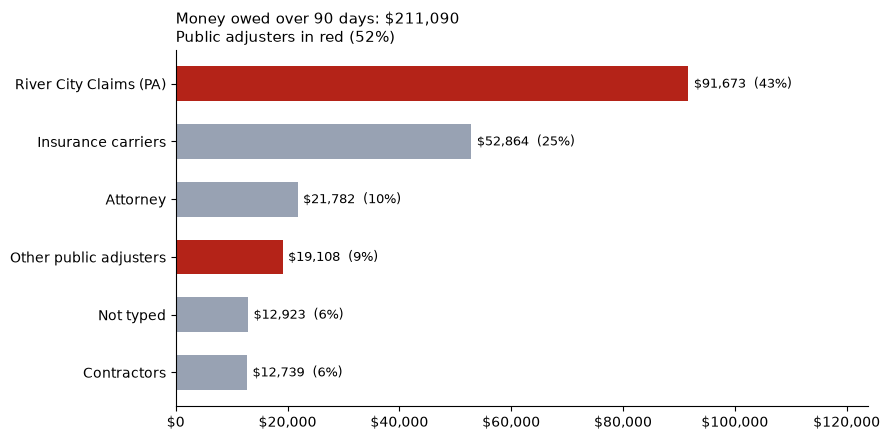

In [7]:
# Memo chart: over-90 balance by payor group, public adjusters in red
plot = over90.drop("Total")["owed"].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.55 * len(plot) + 1.2))
colors = [PA_COLOR if g in (GROUPS["river_city"], GROUPS["public_adjuster"]) else OTHER_COLOR for g in plot.index]
bars = ax.barh(plot.index, plot.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"${v:,.0f}  ({v / total_old:.0%})" for v in plot.values], padding=4, fontsize=9)
ax.set_title(f"Money owed over 90 days: ${total_old:,.0f}\nPublic adjusters in red ({pa_old / total_old:.0%})",
             loc="left", fontsize=11)
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set_xlim(0, plot.max() * 1.35)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

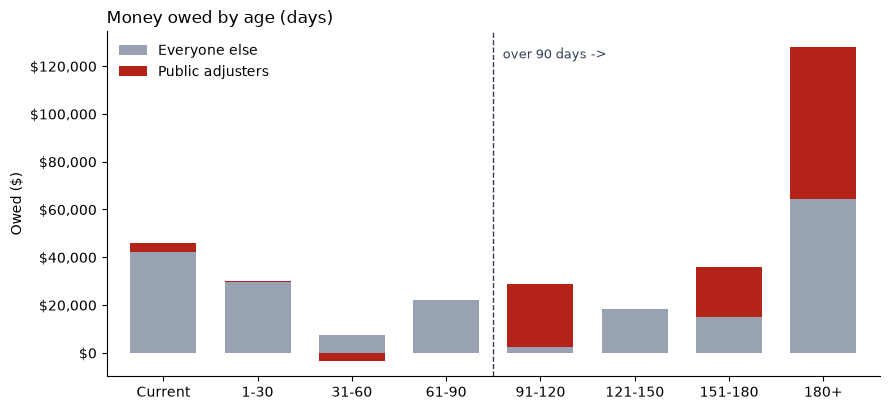

who,Everyone else,Public adjusters
age,,
Current,"42,073.01","3,768.17"
1-30,"29,496.57",487.49
31-60,"7,317.83","-3,324.92"
61-90,"22,075.10",0.00
91-120,"2,568.17","26,282.96"
121-150,"18,370.87",0.00
151-180,"14,881.66","21,015.68"
180+,"64,488.06","63,482.74"


In [8]:
# Age profile: public adjusters vs everyone else
ages = [b for b in BUCKETS.values() if b in set(ar["age"])]
prof = (ar.assign(who=np.where(ar["is_pa"], "Public adjusters", "Everyone else"))
          .pivot_table(index="age", columns="who", values="owed", aggfunc="sum", fill_value=0)
          .reindex(ages, fill_value=0)[["Everyone else", "Public adjusters"]])
ax = prof.plot(kind="bar", stacked=True, figsize=(9, 4.2), color=[OTHER_COLOR, PA_COLOR], width=0.7, rot=0)
ax.axvline(ages.index("91-120") - 0.5, color=INK, ls="--", lw=1)
ax.text(ages.index("91-120") - 0.4, ax.get_ylim()[1] * 0.95, "over 90 days ->", fontsize=9, color=INK, va="top")
ax.set_title("Money owed by age (days)", loc="left"); ax.set_xlabel(""); ax.set_ylabel("Owed ($)")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
prof

## River City Claims accounts
Every River City account, largest first. Fill in what is known about each: why it is unpaid, the last contact, and the next step.

In [9]:
rc_cols = ["address", "age", "balance", "collected", "owed", "collectable", "last_contact", "next_action",
           "promise_date", "updated_at"]
(rc_all[rc_cols].sort_values("owed", ascending=False)
       .assign(updated_at=lambda t: pd.to_datetime(t["updated_at"]).dt.date)
       .reset_index(drop=True))

,address,age,balance,collected,owed,collectable,last_contact,next_action,promise_date,updated_at
0,1510 Mallard Landing – Beacher,180+,"26,143.80",0.00,"26,143.80",0.00,,,None,2026-09-25
1,12165 Ripken Cir N – Stuart,151-180,"19,305.68",0.00,"19,305.68",0.00,,,None,2026-09-25
2,6964 Roundleaf Dr – Shilhavy,180+,"12,792.33",0.00,"12,792.33",0.00,,,None,2026-09-25
3,9 Carr Ln – Jones,180+,"10,782.42",0.00,"10,782.42",0.00,,,None,2026-09-25
4,1655 The Greens Way #2813 – Baron,91-120,"7,485.18",0.00,"7,485.18",0.00,,,None,2026-09-25
5,3532 Garibaldi Way – Burkhart,91-120,"4,069.38",0.00,"4,069.38",0.00,,,None,2026-09-25
6,184 Caspia Ln – Squier,Current,"3,768.17",0.00,"3,768.17",0.00,,,None,2026-09-25
7,153 Tate Ln – Byrd,180+,"3,590.88",0.00,"3,590.88",0.00,,,None,2026-09-25
8,13062 Biggin Church Rd S – Merriam,180+,"3,500.10",0.00,"3,500.10",0.00,,,None,2026-09-25
9,13322 Avery Park Ln – Lara,180+,"1,902.52",0.00,"1,902.52",0.00,,,None,2026-09-25


## Largest accounts over 90 days (all payors)

In [10]:
(old[["payor", "group", "address", "age", "owed", "collected"]]
    .sort_values("owed", ascending=False).head(15).reset_index(drop=True))

,payor,group,address,age,owed,collected
0,River City Claims,River City Claims (PA),1510 Mallard Landing – Beacher,180+,"26,143.80",0.00
1,David Graham Ins Law,Attorney,2005 Mariposa Vista Ln – Williams,180+,"21,782.30",0.00
2,River City Claims,River City Claims (PA),12165 Ripken Cir N – Stuart,151-180,"19,305.68",0.00
3,Rockwall National,Other public adjusters,5277 Crosby Church Rd - Youman,91-120,"14,728.40",0.00
4,River City Claims,River City Claims (PA),6964 Roundleaf Dr – Shilhavy,180+,"12,792.33",0.00
5,Frontline Insurance,Insurance carriers,854 Summer Bay Dr – Ryan,121-150,"11,315.88",0.00
6,River City Claims,River City Claims (PA),9 Carr Ln – Jones,180+,"10,782.42",0.00
7,605 Timber Pond Dr,Not typed,Rambino,180+,"10,325.88",0.00
8,State Farm Insurance,Insurance carriers,699 Sandstone Dr – Petrie,180+,"9,141.24",0.00
9,River City Claims,River City Claims (PA),1655 The Greens Way #2813 – Baron,91-120,"7,485.18",0.00


## Over 90 days, by individual payor

In [11]:
(old.groupby(["payor", "group"]).agg(accounts=("id", "count"), owed=("owed", "sum"))
    .sort_values("owed", ascending=False)
    .assign(share_pct=lambda t: t["owed"] / total_old * 100)
    .head(10).round(1))

,,accounts,owed,share_pct
payor,group,,,
River City Claims,River City Claims (PA),13,"91,673.00",43.40
David Graham Ins Law,Attorney,1,"21,782.30",10.30
State Farm Insurance,Insurance carriers,7,"20,647.00",9.80
Frontline Insurance,Insurance carriers,2,"18,497.90",8.80
Rockwall National,Other public adjusters,1,"14,728.40",7.00
605 Timber Pond Dr,Not typed,1,"10,325.90",4.90
Kin Home Insurance,Insurance carriers,5,"7,182.80",3.40
Servpro Jax Beach,Contractors,1,"4,777.60",2.30
PuroClean,Contractors,2,"4,731.40",2.20


## Notes
- The AR tracker is a snapshot. It stores an age bucket per entry, not invoice or payment dates, so it can't show days-to-pay or trends. QuickBooks *A/R Aging Detail* has the dates.
- Payor type is who pays. A carrier can pay on a claim a public adjuster represents, so the public adjuster share here is a floor, not a ceiling.
- Owed = balance minus collected; it matches the totals management uses.
- Credits (negative owed) are kept in the totals.